# Asalariados a tiempo completo que ganan hasta un salario mínimo

In [ ]:
# Parámetros de la gráfica
SLUG = "empleo"  # carpeta en research/temas/
GRAFICA_ID = "asalariados-hasta-smi"  # id de la gráfica (kebab-case) = nombre del notebook
TITULO = "Asalariados a tiempo completo que ganan hasta un salario mínimo"  # `titulo` de la gráfica en config.json
DESDE = 1976  # inicio de la ventana temporal (METODOLOGIA §2.3)
TIPO = "solo_espana"  # serie_temporal | por_ccaa | solo_espana
VISTA = "lineas"  # `vista` de la gráfica en config.json: lineas | ultimo_anio | proyeccion | categorias
EJE_MAX = None  # `eje_max` de la gráfica en config.json; None = el que piden los datos
UNIDAD = "% de los asalariados a tiempo completo"  # incluye deflactor/PPA si aplica (METODOLOGIA §2.4)
CSV_FORMATO = "es"  # CSV: "es" (separador ; y coma decimal, Excel en español) o "int" (, y punto)
CSV_DECIMALES = 1  # decimales del CSV (el JSON guarda el valor completo)
REFERENCIA = None  # línea horizontal de referencia (p. ej. 100 en un índice); None = sin línea
DIR_SALIDA = None  # solo tests; None = temas/<SLUG>/data/

## 1. Contexto

**Qué mide.** El porcentaje de los asalariados a tiempo completo cuya ganancia bruta del año es menor o igual que el salario mínimo interprofesional (SMI) anual.

**Cómo se lee.** Un valor de 5 significa que uno de cada veinte asalariados a tiempo completo ganó en el año como mucho el salario mínimo. Es la forma de ver a cuántos alcanza directamente el nivel del SMI.

**Limitaciones.**
- La encuesta compara la ganancia de todo el año con el SMI anual y cuenta a quienes han estado de alta al menos dos meses del año, uno de ellos octubre: quien trabajó a tiempo completo solo una parte del año gana menos que el SMI anual aunque cobre más al mes.
- Quien cobra el SMI y recibe algún complemento puede superar ligeramente el SMI anual y quedar fuera.
- Se usa el tiempo completo porque con el tiempo parcial la ganancia anual queda por debajo del SMI aunque la hora se pague por encima; el dato de todos los asalariados va en las notas.
- No hay un indicador comparable en las fuentes internacionales autorizadas: Eurostat y la OCDE publican el nivel del salario mínimo, no cuántos lo cobran.

## 2. Descarga

- **INE, Encuesta Anual de Estructura Salarial** (tabla 28182, «Porcentaje de trabajadores en función de su ganancia con respecto al SMI, respecto al total de trabajadores, por tipo de jornada y sexo»), ambos sexos:
  - `EAES49`: jornada a tiempo completo, de 0 a 1 SMI (la serie de la gráfica);
  - `EAES48`: jornada a tiempo completo, de 1 a 2 SMI (para las notas);
  - `EAES59`: todos los asalariados, de 0 a 1 SMI (para las notas).

In [ ]:
import sys
from pathlib import Path

# Raíz del proyecto (la carpeta con global.json y lib/), buscando hacia arriba desde el directorio de ejecución
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "global.json").exists()), None)
if RAIZ is None:
    raise FileNotFoundError(
        "No se encuentra global.json. Abre el notebook desde su carpeta (temas/<tema>/notebooks/) "
        "dentro del repositorio completo; consulta el README para instalar el entorno."
    )
sys.path.insert(0, str(RAIZ))

from lib import estilos, ine
from lib.writer import construir_grafica_data, write_grafica_data

SERIES = {"EAES49": "espana", "EAES48": "completo_1_2", "EAES59": "todos_0_1"}
datos_ine, fuentes_ine = ine.get(SERIES, desde=DESDE)
print(datos_ine.groupby("serie")["periodo"].agg(["min", "max", "count"]))

               min   max  count
serie                          
completo_1_2  2008  2024     17
espana        2008  2024     17
todos_0_1     2008  2024     17


## 3. Transformación

1. La serie de la gráfica se usa tal como la publica el INE.
2. **Notas:** el tramo de 1 a 2 SMI de los asalariados a tiempo completo y el dato de todos los asalariados (a tiempo completo y parcial), en el primer y el último año.

In [ ]:
def es(v, d=1):
    return estilos.formato_es(v, d)


ancho = datos_ine.pivot(index="periodo", columns="serie", values="valor")
assert ancho.stack().between(0, 100).all(), "porcentaje fuera de rango"
df = datos_ine[datos_ine["serie"] == "espana"][["serie", "periodo", "valor"]]
fuentes = [f for f in fuentes_ine if f.serie == "espana"]

a0, a1 = int(ancho["espana"].dropna().index.min()), int(ancho["espana"].dropna().index.max())
NOTAS = [
    "INE, Encuesta Anual de Estructura Salarial (tabla 28182): asalariados a tiempo completo con una ganancia bruta anual "
    "menor o igual que el salario mínimo interprofesional anual (tramo «de 0 a 1 SMI»), en % del total de asalariados a "
    "tiempo completo, ambos sexos.",
    "La encuesta cuenta a los asalariados que han estado de alta en la Seguridad Social al menos dos meses del año, uno de "
    "ellos octubre, y compara la ganancia de todo el año con el SMI anual: quien trabajó solo una parte del año puede ganar "
    "menos que el SMI anual aunque cobre más al mes; quien cobra el SMI con algún complemento puede quedar por encima.",
    f"Asalariados a tiempo completo con una ganancia de entre 1 y 2 veces el SMI anual: {es(ancho.loc[a0, 'completo_1_2'])} % "
    f"en {a0} y {es(ancho.loc[a1, 'completo_1_2'])} % en {a1}.",
    f"Todos los asalariados (a tiempo completo y parcial) con una ganancia anual de hasta un SMI: "
    f"{es(ancho.loc[a0, 'todos_0_1'])} % en {a0} y {es(ancho.loc[a1, 'todos_0_1'])} % en {a1}. Incluye a quienes trabajan "
    "a tiempo parcial, cuya ganancia anual queda por debajo del SMI aunque cobren por hora más que el mínimo.",
    "Motivo de solo_espana: las fuentes internacionales autorizadas publican el nivel del salario mínimo, no qué parte de "
    "los asalariados lo cobra.",
]
for n in NOTAS:
    print("-", n)

- INE, Encuesta Anual de Estructura Salarial (tabla 28182): asalariados a tiempo completo con una ganancia bruta anual menor o igual que el salario mínimo interprofesional anual (tramo «de 0 a 1 SMI»), en % del total de asalariados a tiempo completo, ambos sexos.
- La encuesta cuenta a los asalariados que han estado de alta en la Seguridad Social al menos dos meses del año, uno de ellos octubre, y compara la ganancia de todo el año con el SMI anual: quien trabajó solo una parte del año puede ganar menos que el SMI anual aunque cobre más al mes; quien cobra el SMI con algún complemento puede quedar por encima.
- Asalariados a tiempo completo con una ganancia de entre 1 y 2 veces el SMI anual: 33,5 % en 2008 y 54,5 % en 2024.
- Todos los asalariados (a tiempo completo y parcial) con una ganancia anual de hasta un SMI: 8,9 % en 2008 y 18,3 % en 2024. Incluye a quienes trabajan a tiempo parcial, cuya ganancia anual queda por debajo del SMI aunque cobren por hora más que el mínimo.
- Motivo

## 4. Visualización

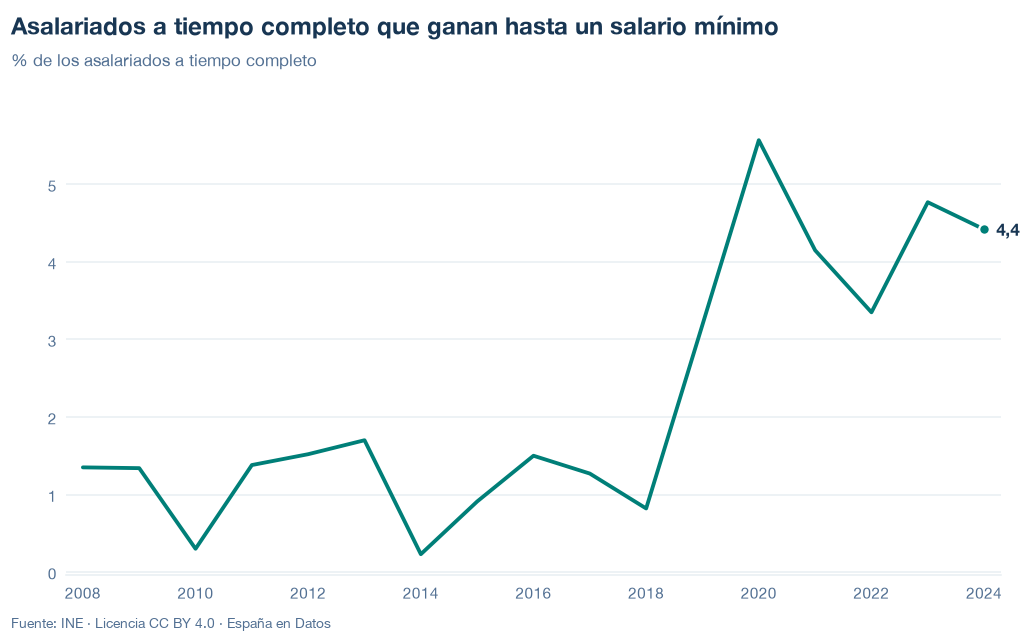

In [ ]:
datos = construir_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
)
fig = estilos.figura(datos, titulo=TITULO, vista=VISTA, eje_max=EJE_MAX)
estilos.mostrar(fig)

## 5. Exportación

Escribe `data/<id>.json` (validado contra el esquema) y `data/<id>.csv`, el mismo CSV que se descarga en la web.

In [ ]:
salida = Path(DIR_SALIDA) if DIR_SALIDA else RAIZ / "temas" / SLUG / "data"
ruta = write_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
    path=salida / f"{GRAFICA_ID}.json", csv_formato=CSV_FORMATO, csv_decimales=CSV_DECIMALES,
)
print(f"escrito: data/{ruta.name} y data/{ruta.stem}.csv")  # sin rutas locales en las salidas publicadas

escrito: data/asalariados-hasta-smi.json y data/asalariados-hasta-smi.csv


## 6. Fuentes, notas y licencia

- INE, Encuesta Anual de Estructura Salarial, tabla 28182: series `EAES49` (gráfica), `EAES48` y `EAES59` (notas).

La fecha de consulta de cada serie está en `fuentes` del JSON.

**Licencia:** datos, gráficos y textos CC BY 4.0; código MIT. Cita a España en Datos.